# Supplementary Fig. 5a: yield of single-units per site, by spike sorter

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of Supplementary Fig. 5: number of sorted 'single-units' per site in cortex (bars: median yield per site over layers; error bars: 95% confidence interval) for the Marques-Smith recording (M), the biophysical models of the spontaneous (NS) and evoked (E) regimes, the synthetic model (S), the Horvath recording (H) and the dense-probe biophysical model (DS), for each spike sorter (ks4, ks3, ks2.5, ks2, ks, hs). The coloured horizontal lines are the theoretical yields of the models (active ground truth units within 50 um of the probe, per site). Source data and svg are saved in figures/8_source_data/supp_fig5a/.

**method (as in the paper's notebook supp_fig5_A_ks4_undersampling.ipynb)**
* sortings of the first 10 minutes of each recording (`dataset/01_intermediate/sorting/`, downloaded with `0_download_sortings.ipynb`)
* yield of a layer = number of units labelled 'good' by Kilosort (all units for Kilosort and Herdingspikes, which do not label units) divided by the number of sites of the layer
* theoretical yield of a layer = number of ground truth units with at least one spike in the first 10 minutes divided by the number of sites of the layer; the plotted line is the median over layers (dense probe: layer 1 from depth 1, layers 2/3 from depths 1 and 2, layers 4 and 5 from depth 2, layer 6 from depth 3; synthetic model: 250 units / 384 sites)

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
from matplotlib import pyplot as plt
import spikeinterface as si
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.analysis.failures import the_yield

# SORTINGS (first 10 minutes) and RECORDINGS (sites and their layers)
SORTING_ROOT = "dataset/01_intermediate/sorting"
SORTERS = {"ks4": "SortingKS4_10m", "ks3": "SortingKS3_10m", "ks2.5": "SortingKS2_5_10m", "ks2": "SortingKS2_10m", "ks": "SortingKS_10m", "hs": "SortingHS_10m"}
# experiment: (sorting folders, recording paths); dense probes are sorted by depth (1 to 3)
DATASETS = {
    "M": (["marques"], ["dataset/00_raw/recording_marques_smith"]),
    "NS": (["npx_spont"], ["dataset/00_raw/recording_npx_spont"]),
    "E": (["npx_evoked"], ["dataset/00_raw/recording_npx_evoked"]),
    "S": (["buccino"], ["dataset/00_raw/recording_buccino"]),
    "H": ([f"horvath/probe_{i}" for i in (1, 2, 3)], [f"dataset/00_raw/recording_horvath_probe{i}" for i in (1, 2, 3)]),
    "DS": ([f"dense_probe{i}" for i in (1, 2, 3)], [f"dataset/00_raw/recording_dense_probe{i}" for i in (1, 2, 3)]),
}
# ground truth of the simulations (all units within 50 um of the probe), restricted to the first 10 minutes below
GT_PATHS = {"NS": "dataset/00_raw/ground_truth_npx_spont_10m", "E": "dataset/00_raw/ground_truth_npx_evoked_10m",
            "DS1": "dataset/00_raw/ground_truth_dense_probe1", "DS2": "dataset/00_raw/ground_truth_dense_probe2", "DS3": "dataset/00_raw/ground_truth_dense_probe3"}
DURATION_SEC = 600
LAYERS = ["L1", "L2/3", "L4", "L5", "L6"]
EXPERIMENTS = ["M", "NS", "E", "S", "H", "DS"]
N_UNITS_SYNTHETIC = 250             # number of ground truth units of the synthetic model (all in layer 5, 384 sites)

# FIGURE SETTINGS
cl = {"COLOR_NV": [0.6, 0.6, 0.6], "COLOR_NS": [0.9, 0.14, 0.15], "COLOR_NB": [0.22, 0.5, 0.72], "COLOR_NE": [1, 0.49, 0], "COLOR_HV": "k", "COLOR_HS": np.array([26, 152, 80]) / 255}
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}
legend_cfg = {"frameon": False, "handletextpad": 0.5}

## Yield per site

In [2]:
%%time

dfs = []
for exp, (folders, rec_paths) in DATASETS.items():
    for depth, (folder, rec_path) in enumerate(zip(folders, rec_paths), start=1):
        sort_paths = [f"{SORTING_ROOT}/{folder}/{name}" for name in SORTERS.values()]
        d = the_yield.get_yield_per_site(list(SORTERS), [exp] * len(SORTERS), sort_paths, rec_path)
        d["depth"] = depth if len(folders) > 1 else np.nan
        dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
df = df[df["layer"].isin(LAYERS)]                      # sites and units in cortex
df.rename(columns={"experiments": "experiment", "sorters": "sorter"}, inplace=True)
display(df.groupby(["experiment", "sorter"])["yield per site"].median().unstack().loc[EXPERIMENTS, list(SORTERS)].round(2))

sorter,ks4,ks3,ks2.5,ks2,ks,hs
experiment,,,,,,
M,0.25,0.05,0.93,3.26,9.86,0.36
NS,0.57,0.46,1.89,3.43,5.87,0.49
E,0.94,0.99,0.87,0.96,2.59,0.76
S,0.98,0.91,1.08,3.94,3.27,0.60
H,0.34,0.53,1.16,2.38,9.70,0.31
DS,0.49,0.59,1.38,2.94,4.39,0.67


CPU times: user 279 ms, sys: 9.84 ms, total: 289 ms
Wall time: 302 ms


## Theoretical yield per site

In [3]:
%%time

def gt_yield(exp, gt_path, rec_path):
    """ground truth yield per site and layer for the first 10 minutes (silent units are dropped)"""
    Gt = si.load_extractor(gt_path)
    Gt = Gt.frame_slice(0, int(DURATION_SEC * Gt.get_sampling_frequency()))
    return the_yield.get_gt_yield_per_site_from_extractors(exp, Gt, si.load_extractor(rec_path))

gt_ns = gt_yield("NS", GT_PATHS["NS"], DATASETS["NS"][1][0])
gt_e = gt_yield("E", GT_PATHS["E"], DATASETS["E"][1][0])
gt_ds = {i: gt_yield(f"DS{i}", GT_PATHS[f"DS{i}"], DATASETS["DS"][1][i - 1]) for i in (1, 2, 3)}


def layer_yield(d, layer):
    return d[d["layer"] == layer]["yield per site (theory)"].values

# dense probe: layer 1 from depth 1, layer 2/3 from depths 1 and 2, layers 4 and 5 from depth 2, layer 6 from depth 3
ds_layers = {"L1": layer_yield(gt_ds[1], "L1"), "L2/3": np.concatenate([layer_yield(gt_ds[1], "L2/3"), layer_yield(gt_ds[2], "L2/3")]), "L4": layer_yield(gt_ds[2], "L4"),
             "L5": layer_yield(gt_ds[2], "L5"), "L6": layer_yield(gt_ds[3], "L6")}
theory = pd.DataFrame([
    {"experiment": "NS", "yield per site (theory)": gt_ns["yield per site (theory)"].median()},
    {"experiment": "E", "yield per site (theory)": gt_e["yield per site (theory)"].median()},
    {"experiment": "S", "yield per site (theory)": N_UNITS_SYNTHETIC / 384},
    {"experiment": "DS", "yield per site (theory)": np.median([np.median(v) for v in ds_layers.values()])}])
display(theory)

1388
nb of silent gt units: 0


1836


nb of silent gt units: 0
287
nb of silent gt units: 0
770
nb of silent gt units: 0
1123


nb of silent gt units: 0


,experiment,yield per site (theory)
0,NS,6.882353
1,E,8.442308
2,S,0.651042
3,DS,5.272727


CPU times: user 1 s, sys: 6.11 ms, total: 1.01 s
Wall time: 1.01 s


## Plot, same as the paper's panel a

In [4]:
def plot_source_data(df: pd.DataFrame, theory: pd.DataFrame):
    """Median yield of single-units per site over layers (bars) with 95% confidence intervals (error bars) for each spike sorter and experiment, and theoretical yields (horizontal lines)"""

    fig, ax = plt.subplots(figsize=(3, 1))
    sns.barplot(df, x="sorter", y="yield per site", hue="experiment", errorbar=("ci", 95), hue_order=EXPERIMENTS, order=list(SORTERS), seed=0,
                palette=[cl["COLOR_NV"], cl["COLOR_NS"], cl["COLOR_NE"], cl["COLOR_NB"], cl["COLOR_HV"], cl["COLOR_HS"]], alpha=0.4, gap=0.1, ax=ax)

    # theoretical yield
    th = theory.set_index("experiment")["yield per site (theory)"]
    for s_i in range(len(SORTERS)):
        ax.scatter(np.array([-0.2, -0.07, 0.07, 0.3]) + s_i, [th["NS"], th["E"], th["S"], th["DS"]], marker="_", s=5, linewidth=1,
                   color=[cl["COLOR_NS"], cl["COLOR_NE"], cl["COLOR_NB"], cl["COLOR_HS"]])
    ax.set_yscale("log")

    # show logarithmic ticks
    ax.tick_params(which="both")
    ax.yaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, numticks=5))
    ax.yaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10.0, subs=np.arange(0, 10, 1), numticks=11))
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    # disconnect axes (R style)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.spines["right"].set_visible(False)
    ax.set_ylabel("Number of isolated single-units\nper site (ratio)")
    ax.set_xlabel("Spike sorters")
    ax.legend().remove()

    # legend of the paper
    fig.text(0.62, 1.30, "Most sorters undersample the ground truth cortical population", fontsize=7, fontweight="bold", family="Arial", ha="left")
    fig.text(1.02, 1.0, "Neuropixels", fontsize=6.5, fontweight="bold", family="Arial", ha="left", transform=ax.transAxes)
    fig.text(1.62, 0.9, "Dense probe", fontsize=6.5, fontweight="bold", family="Arial", ha="left", transform=ax.transAxes)
    labels = {"M": "M : Marques-Smith", "NS": "NS : Biophy. Spont", "E": "E : Biophy. Evoked", "S": "S : Synthetic model", "H": "H: Horvath", "DS": "DS: Biophy. Spont"}
    colors = {"M": cl["COLOR_NV"], "NS": cl["COLOR_NS"], "E": cl["COLOR_NE"], "S": cl["COLOR_NB"], "H": cl["COLOR_HV"], "DS": cl["COLOR_HS"]}
    for i, e in enumerate(["M", "NS", "E", "S"]):
        y = 0.88 - 0.17 * i
        ax.add_patch(matplotlib.patches.Rectangle((1.02, y - 0.05), 0.16, 0.11, transform=ax.transAxes, color=colors[e], alpha=0.4, clip_on=False))
        ax.text(1.22, y, labels[e], transform=ax.transAxes, fontsize=5.5, va="center")
    for i, e in enumerate(["H", "DS"]):
        y = 0.75 - 0.17 * i
        ax.add_patch(matplotlib.patches.Rectangle((1.62, y - 0.05), 0.16, 0.11, transform=ax.transAxes, color=colors[e], alpha=0.6, clip_on=False))
        ax.text(1.82, y, labels[e], transform=ax.transAxes, fontsize=5.5, va="center")
    return fig

## Plot and save the figure and the source data

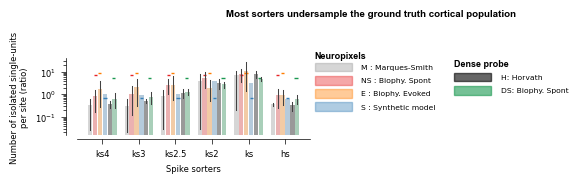

In [5]:
fig = plot_source_data(df, theory)
os.makedirs("figures/8_source_data/supp_fig5a", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig5a/supp_fig5a.svg", bbox_inches="tight", **savefig_cfg)
with pd.ExcelWriter("figures/8_source_data/supp_fig5a/supp_fig5a.xlsx") as writer:
    df.to_excel(writer, sheet_name="yield_per_site", index=False)
    theory.to_excel(writer, sheet_name="theoretical_yield", index=False)

## Check: replot from the saved source data

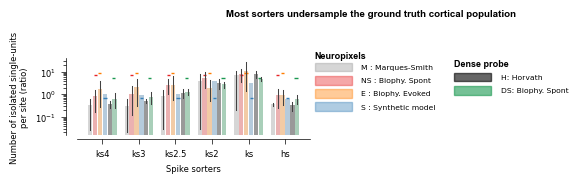

In [6]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig5a/supp_fig5a.xlsx", sheet_name="yield_per_site")
theory_loaded = pd.read_excel("figures/8_source_data/supp_fig5a/supp_fig5a.xlsx", sheet_name="theoretical_yield")
fig = plot_source_data(df_loaded, theory_loaded)